Protocolo ativo: modelo global treinado/agregado e redistribuído. Resultados do fluxo anterior estão arquivados e não sustentam a decisão atual.

In [ ]:
from pathlib import Path
import sys
PROJECT_ROOT=Path.cwd().resolve()
while not (PROJECT_ROOT/'requirements.txt').exists() and PROJECT_ROOT!=PROJECT_ROOT.parent:
    PROJECT_ROOT=PROJECT_ROOT.parent
sys.path.insert(0,str(PROJECT_ROOT))


## Gráficos comparativos

Barras separadas para global, local e referência privada. As posições são ordenadas pela PR-AUC local dentro de cada dataset, sem misturar as duas origens. As barras de erro representam desvio entre seeds, não intervalos de confiança populacionais. Local refere-se ao modelo após treino da última ronda, antes da agregação; global é o modelo agregado e redistribuído, da mesma arquitetura indicada na linha.

### FedAvg — dev

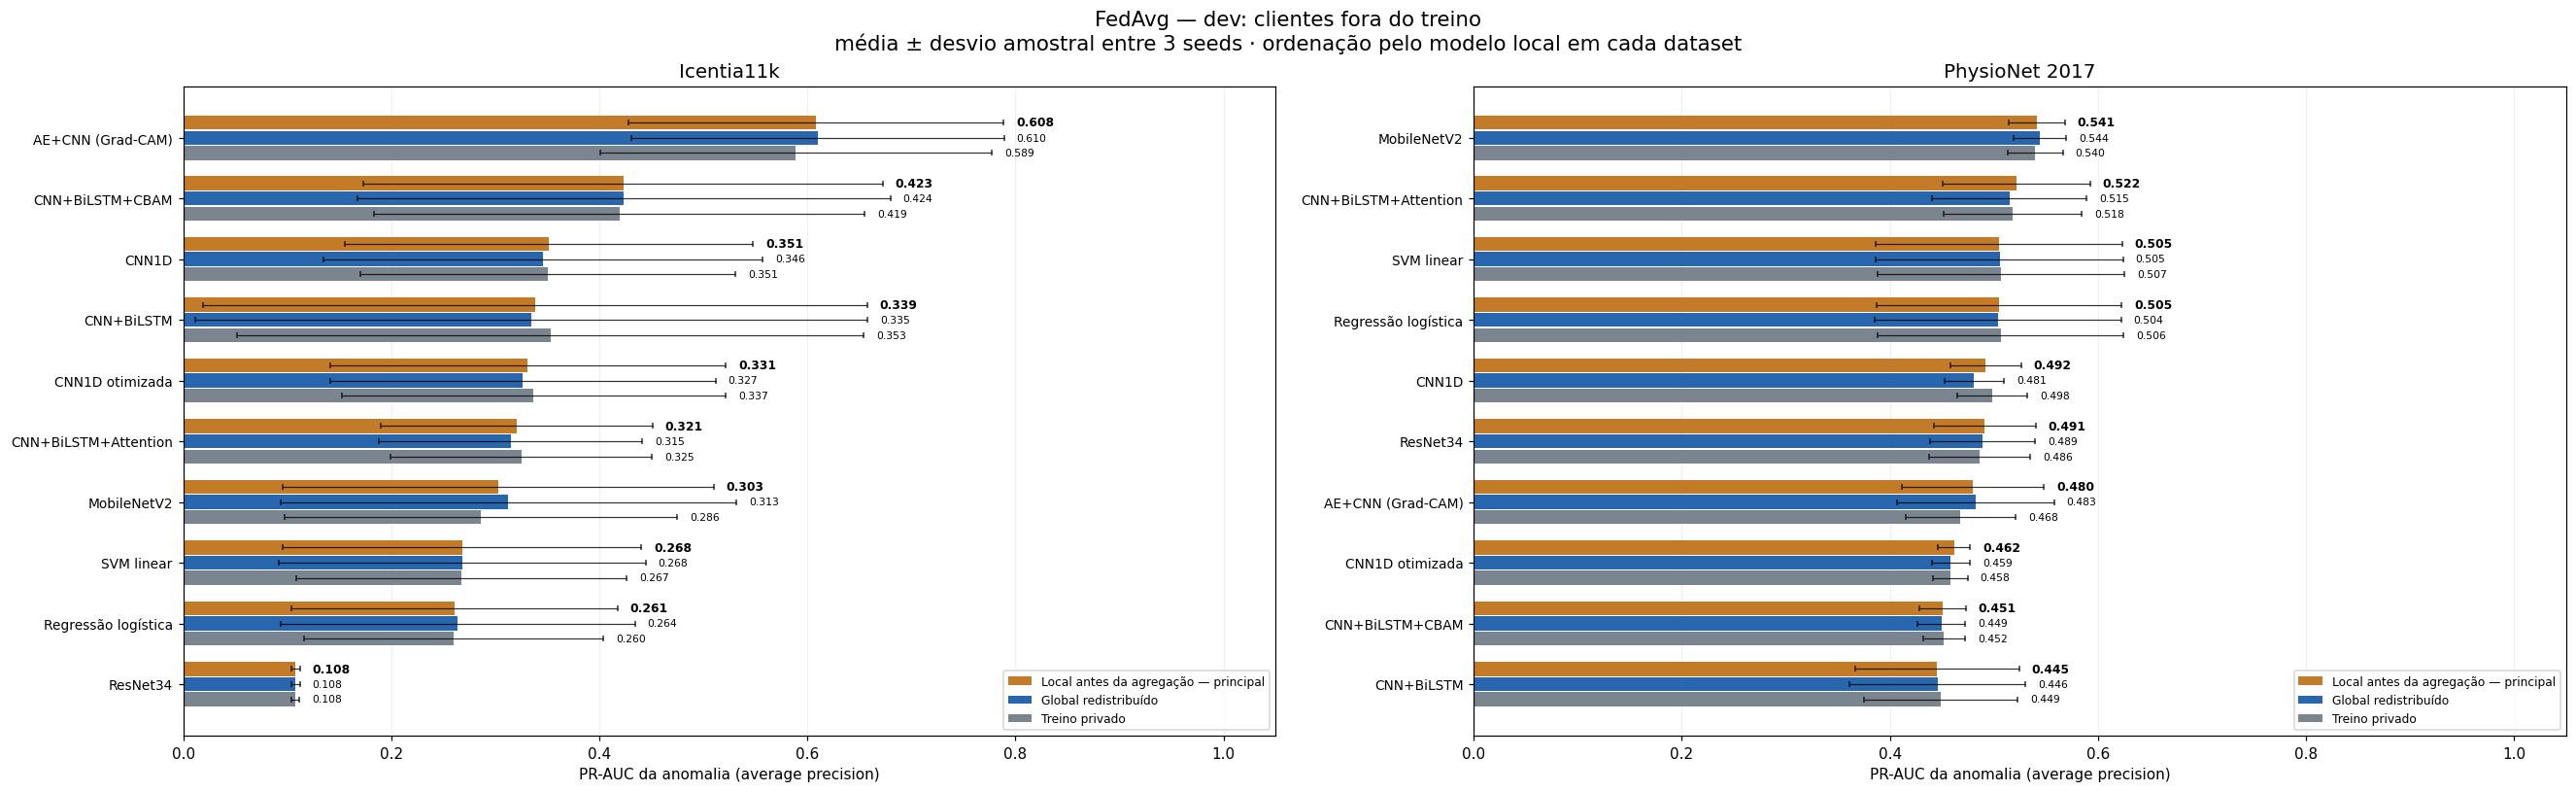

In [1]:
from support.experiment_plots import render_comparison
render_comparison('fedavg', split='dev', experiment=None)

### FedAvg — holdout local

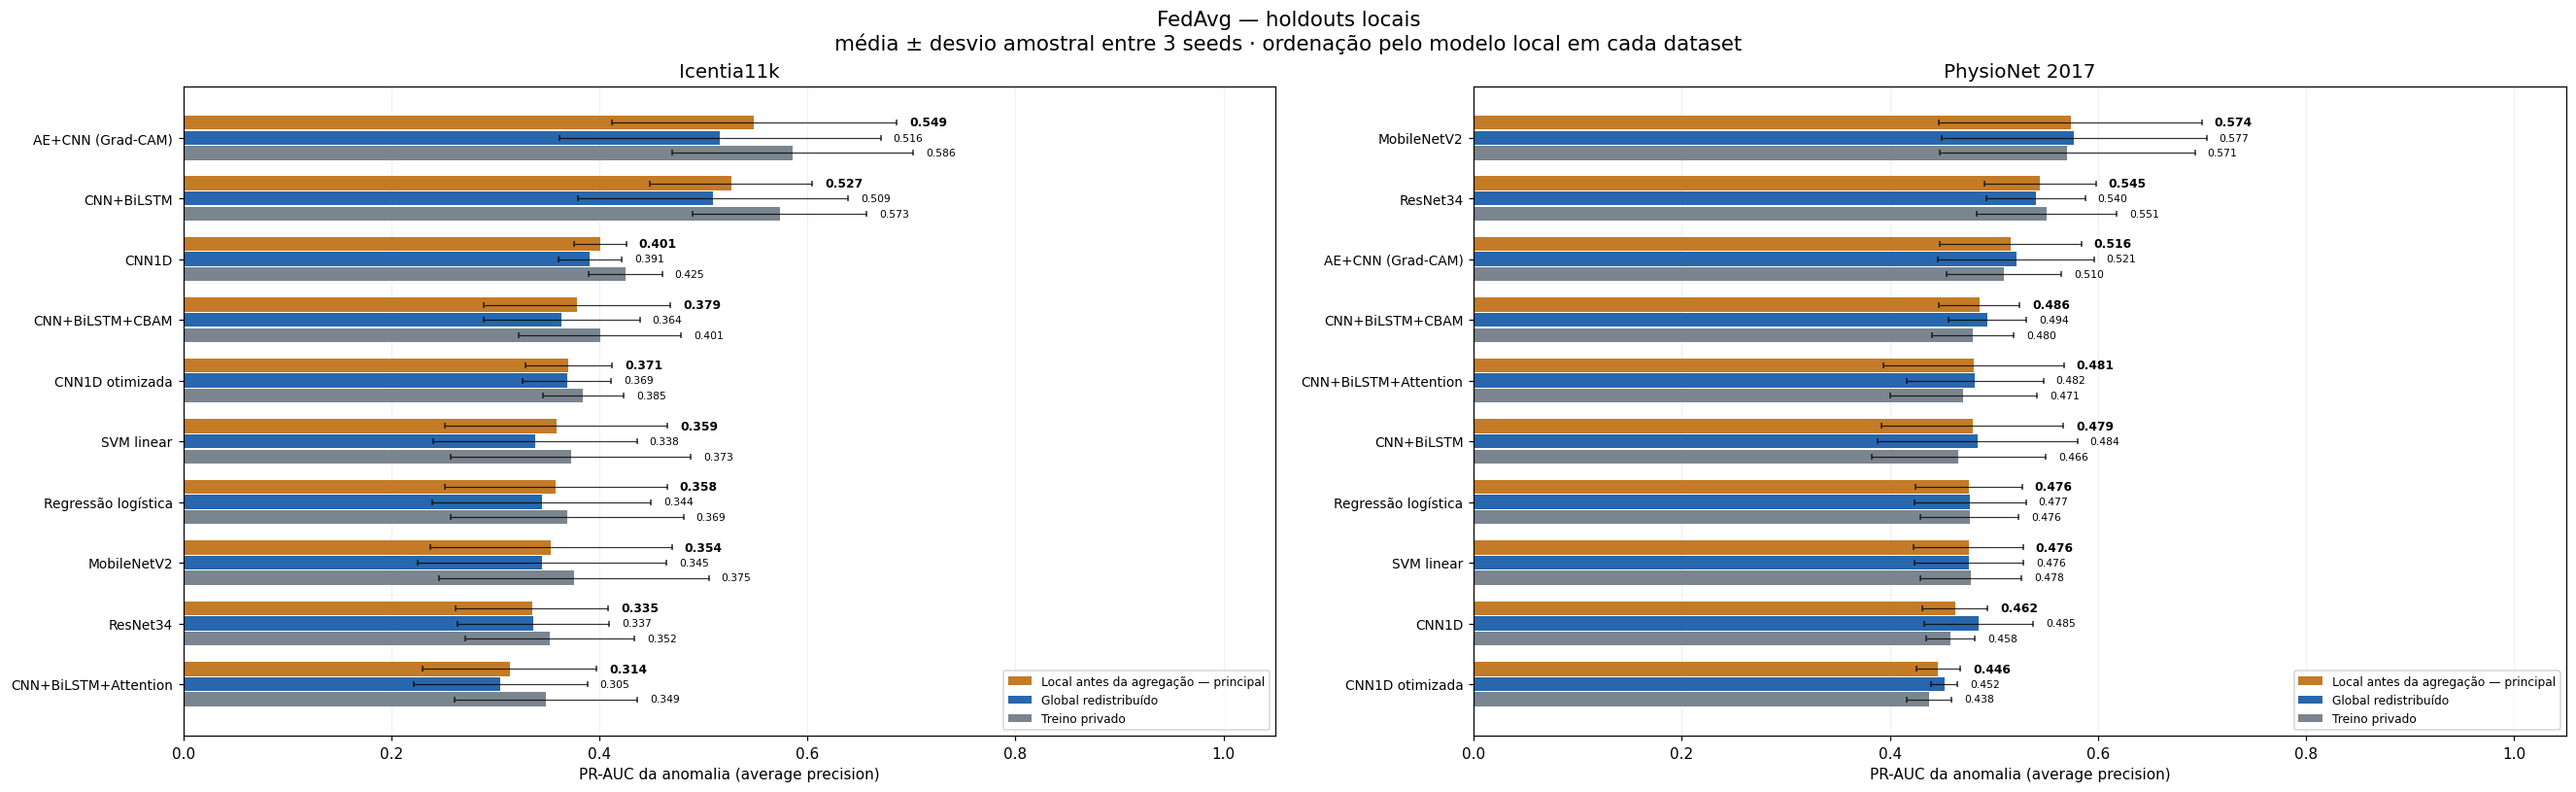

In [1]:
from support.experiment_plots import render_comparison
render_comparison('fedavg', split='train', experiment=None)

In [1]:
from support.federated_global.report import render_fedavg
render_fedavg()

# FedAvg corrigido — modelo global redistribuído

Apenas modelos com parâmetros compatíveis; RF/KNN e as duas GRU excluídos. Três rondas, três seeds de treino e dados fixos à seed 2026. O servidor agrega parâmetros ponderados pelo fit e redistribui o modelo em cada ronda. As réplicas finais dos clientes têm exatamente o mesmo estado que o global. Não há ensemble de previsões neste protocolo. Resultados anteriores são históricos.

{'status': 'complete', 'completed': 60, 'expected': 60}

## Modelo global entregue aos clientes — train

dataset,model,approach,split,pr_auc_ap,roc_auc,recall,far,f1,pr_auc_std,seeds
icentia11k,Autoencoder_CNN_GradCAM,global,train,0.51601,0.67726,0.37847,0.34287,0.14713,0.15453,3
icentia11k,CNN_BiLSTM,global,train,0.50911,0.61945,0.56250,0.43853,0.24530,0.13006,3
icentia11k,CNN1D,global,train,0.39110,0.51868,0.48264,0.45129,0.23956,0.03031,3
icentia11k,CNN1D_Optimized,global,train,0.36881,0.50411,0.51042,0.52856,0.21652,0.04247,3
icentia11k,CNN_BiLSTM_CBAM,global,train,0.36364,0.51707,0.33681,0.26918,0.20216,0.07517,3
icentia11k,MobileNetV2,global,train,0.34525,0.46941,0.42361,0.41948,0.15943,0.11959,3
icentia11k,LogReg,global,train,0.34449,0.42587,0.55903,0.62700,0.20913,0.10523,3
icentia11k,SVM,global,train,0.33800,0.42935,0.56597,0.64757,0.20745,0.09809,3
icentia11k,ResNet34,global,train,0.33650,0.44429,0.21181,0.15755,0.11756,0.07314,3
icentia11k,CNN_BiLSTM_Attention,global,train,0.30488,0.47550,0.69097,0.68150,0.21310,0.08358,3


## Modelo global entregue aos clientes — dev

dataset,model,approach,split,pr_auc_ap,roc_auc,recall,far,f1,pr_auc_std,seeds
icentia11k,Autoencoder_CNN_GradCAM,global,dev,0.60990,0.75311,0.43519,0.21937,0.26542,0.17904,3
icentia11k,CNN_BiLSTM_CBAM,global,dev,0.42374,0.61928,0.36111,0.28214,0.27540,0.25624,3
icentia11k,CNN1D,global,dev,0.34614,0.50663,0.63889,0.60238,0.29689,0.21114,3
icentia11k,CNN_BiLSTM,global,dev,0.33471,0.44876,0.51852,0.59654,0.19083,0.32310,3
icentia11k,CNN1D_Optimized,global,dev,0.32662,0.48253,0.60185,0.67846,0.23876,0.18497,3
icentia11k,CNN_BiLSTM_Attention,global,dev,0.31483,0.52065,0.76852,0.77424,0.27978,0.12667,3
icentia11k,MobileNetV2,global,dev,0.31253,0.44230,0.40741,0.49957,0.14415,0.21907,3
icentia11k,SVM,global,dev,0.26806,0.45326,0.47222,0.52987,0.17705,0.17636,3
icentia11k,LogReg,global,dev,0.26412,0.44345,0.45370,0.51180,0.17556,0.17005,3
icentia11k,ResNet34,global,dev,0.10791,0.16261,0.09259,0.19632,0.03205,0.00410,3


{'signature': '3ecc65afd19a0d2a69ae3f2a44eb2e89f76e3c3a50a0b5e9aa0b25af1c8a1f28', 'selected': {'icentia11k': ['Autoencoder_CNN_GradCAM', 'CNN_BiLSTM', 'CNN1D'], 'physionet2017': ['MobileNetV2', 'ResNet34', 'Autoencoder_CNN_GradCAM']}, 'criterion': 'mean AP on local holdouts of the delivered GLOBAL model; three fixed-data seeds; ROC-AUC tie-break', 'exploratory': True, 'excluded': ['RandomForest', 'KNN', 'GRU5', 'GRU_Simple']}

Ranking para selecionar candidatos: AP do modelo global entregue, nos holdouts locais; ROC-AUC desempata. Os modelos locais pré-agregação são diagnóstico separado. Holdout já usado na pesquisa: seleção exploratória; test reservado.